# Learning-rate tuning results

This notebook reads the runs of one tuning round and helps pick a learning rate.
It works for every round: set `TUNE_DIR` in the next cell to the folder you want.

| folder | job | what was run |
|---|---|---|
| `runs_tune/` | `jobs/tune.sbatch` (round 1) | lr 1e-5 / 3e-5 / 1e-4 × 3 conditions, size 1000 |
| `runs_tune2/` | `jobs/tune.sbatch` (round 2) | lr 3e-6 / 5e-6 / 1e-5 × 3 conditions, size 1000 |
| `runs_tune_full/` | `jobs/tune_full.sbatch` | lr 3e-6 / 1e-5 / 3e-5, uniform only, full size |

Within a round, everything except the learning rate (and the condition) is the same for every run.

**Where the results are:**
```
<TUNE_DIR>/lr<LR>/<condition>_n<size>_seed0/run_info.json   settings + final scores
<TUNE_DIR>/lr<LR>/<condition>_n<size>_seed0/dev_curve.csv   dev loss every eval_every steps
```

**What we look at, in order:**
1. A table of the final scores for every run.
2. Which learning rate is best (for each condition, if there are several), and whether it is at the edge of the grid.
3. The dev-loss curves, to check that training behaved sensibly.
4. Whether the step budget was long enough.

In [30]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths below are relative to the repository root. If the notebook was started
# from inside notebooks/, move up one level.
if Path.cwd().name == "notebooks":
    os.chdir("..")

TUNE_DIR = Path("runs_tune_full2")  # or runs_tune2 (size 1000, round 2), runs_tune (round 1)

# Fixed order for tables and plots. Only the conditions present in TUNE_DIR are used.
ALL_CONDITIONS = ["uniform", "length", "joint"]

## 1. Load every run

Each run folder has a `run_info.json`. We read them all into one table, one row per run.

In [31]:
rows = []
for info_file in sorted(TUNE_DIR.glob("lr*/*/run_info.json")):
    info = json.loads(info_file.read_text())
    rows.append(
        {
            "condition": info["condition"],
            "size": info["size"],
            "lr": info["lr"],
            "best_step": info["best_step"],
            "steps": info["steps"],
            "dev_loss": info["best_dev_loss"],
            "dev_bleu": info["dev_bleu_greedy"],
            "run_dir": info_file.parent,
        }
    )
runs = pd.DataFrame(rows)

CONDITIONS = [c for c in ALL_CONDITIONS if c in set(runs["condition"])]
LRS = sorted(runs["lr"].unique())

print(f"{TUNE_DIR}: size {', '.join(sorted(set(runs['size'])))}, conditions {CONDITIONS}")
print(f"found {len(runs)} of {len(LRS) * len(CONDITIONS)} runs")
runs.drop(columns="run_dir")

runs_tune_full2: size full, conditions ['uniform']
found 2 of 2 runs


,condition,size,lr,best_step,steps,dev_loss,dev_bleu
0,uniform,full,0.000010,3300,4800,2.110437,16.061585
1,uniform,full,0.000003,4600,4800,2.099381,16.059311


If some runs are missing, those tasks are still running or failed.
Check `logs/slurm/mt-tune-*.out` for the missing ones.

## 2. Compare learning rates

Two tables, rows = learning rate, columns = condition:
- **dev BLEU** (higher is better): the metric we actually care about.
- **dev loss** (lower is better): what checkpoint selection used. Mainly a sanity check.

Rough rule of thumb: BLEU differences below about 0.5 are within seed noise, so treat
those learning rates as equally good.

In [32]:
bleu = runs.pivot(index="lr", columns="condition", values="dev_bleu")[CONDITIONS]
loss = runs.pivot(index="lr", columns="condition", values="dev_loss")[CONDITIONS]

# Show learning rates as 1e-05 instead of 0.00001.
print("dev BLEU (higher is better)")
display(bleu.rename(index="{:g}".format).round(2))
print("dev loss (lower is better)")
display(loss.rename(index="{:g}".format).round(4))

dev BLEU (higher is better)


condition,uniform
lr,
3e-06,16.06
1e-05,16.06


dev loss (lower is better)


condition,uniform
lr,
3e-06,2.0994
1e-05,2.1104


In [33]:
# Best learning rate for each condition, by dev BLEU.
best_lr = bleu.idxmax()
print("best learning rate per condition:")
for condition in CONDITIONS:
    print(f"  {condition:8s} lr = {best_lr[condition]:g}  (BLEU {bleu[condition].max():.2f})")

if len(CONDITIONS) > 1:
    # Average over conditions: the best single learning rate if we use one for everyone.
    mean_bleu = bleu.mean(axis=1)
    print(f"\nmean BLEU over conditions, per learning rate:")
    for lr, value in mean_bleu.items():
        print(f"  lr = {lr:g}: {value:.2f}")

    if best_lr.nunique() == 1:
        print(f"\n-> Same best learning rate for every condition: use lr = {best_lr.iloc[0]:g} for all.")
    else:
        print(
            "\n-> The best learning rate differs between conditions. Either use each condition's own best,"
            " or check whether one learning rate is within ~0.5 BLEU of the best everywhere and use that."
        )

# If the best value is the smallest or largest one tried, the real optimum may lie beyond the grid.
for condition in CONDITIONS:
    if best_lr[condition] in (LRS[0], LRS[-1]):
        side = "smallest" if best_lr[condition] == LRS[0] else "largest"
        print(f"\nNote: for {condition}, the best lr is the {side} one tried ({best_lr[condition]:g}). "
              "Consider one more value beyond it, unless the gain from the previous value is tiny.")

best learning rate per condition:
  uniform  lr = 1e-05  (BLEU 16.06)

Note: for uniform, the best lr is the largest one tried (1e-05). Consider one more value beyond it, unless the gain from the previous value is tiny.


## 3. Dev-loss curves

One panel per condition, one line per learning rate (darker = higher learning rate).
The dot marks the selected checkpoint (lowest dev loss). Step 0 is the pretrained model.

What to look for:
- **Curve goes down, then flattens or rises again:** normal. Rising means overfitting;
  checkpoint selection takes care of it.
- **Curve shoots up right away:** learning rate too high.
- **Curve barely moves:** learning rate too low (or too few steps).

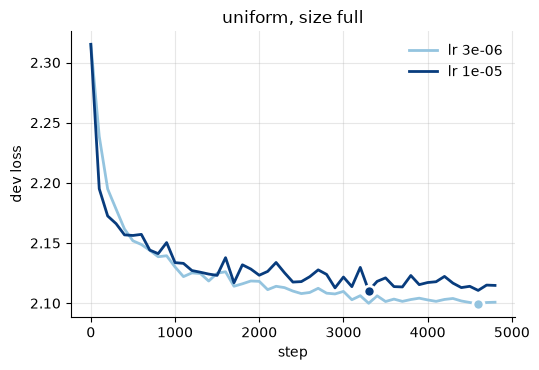

In [34]:
# One blue hue, light -> dark for low -> high learning rate (the learning rates are ordered).
colour = {lr: plt.cm.Blues(x) for lr, x in zip(LRS, np.linspace(0.4, 0.95, len(LRS)))}

# squeeze=False: axes is always a 2D array, even with a single condition (one panel).
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(4.5 * len(CONDITIONS) + 1, 3.8),
                         sharey=True, squeeze=False)
axes = axes[0]
for ax, condition in zip(axes, CONDITIONS):
    for _, run in runs[runs["condition"] == condition].sort_values("lr").iterrows():
        curve = pd.read_csv(run["run_dir"] / "dev_curve.csv")
        ax.plot(curve["step"], curve["dev_loss"], color=colour[run["lr"]], linewidth=2, label=f"lr {run['lr']:g}")
        ax.plot(run["best_step"], run["dev_loss"], "o", color=colour[run["lr"]], markersize=8,
                markeredgecolor="white", markeredgewidth=2)
    ax.set_title(f"{condition}, size {run['size']}")
    ax.set_xlabel("step")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("dev loss")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## 3b. Train and dev loss, one panel per run

Rows = condition, columns = learning rate. Each panel shows the training loss (averaged over
the steps since the previous evaluation) and the dev loss. The dot is the selected checkpoint.

What to look for:
- **Both going down:** still learning; if this lasts to the end, more steps might help.
- **Train going down, dev flat or rising:** the model is memorising the training data (overfitting).
- **Gap between the two lines growing:** same thing, more gradually.

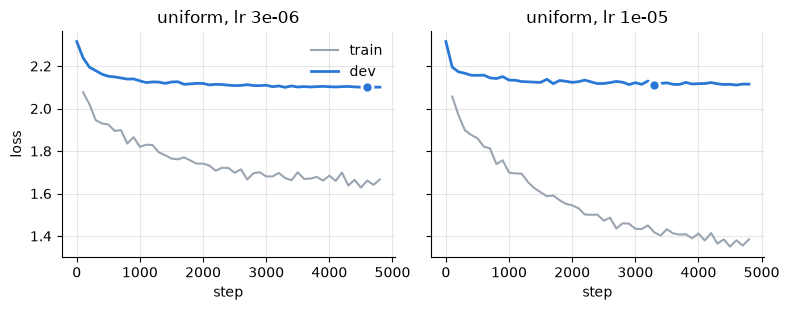

In [35]:
fig, axes = plt.subplots(len(CONDITIONS), len(LRS), figsize=(4 * len(LRS), 3.2 * len(CONDITIONS)),
                         sharex=True, sharey=True, squeeze=False)
for i, condition in enumerate(CONDITIONS):
    for j, lr in enumerate(LRS):
        ax = axes[i, j]
        match = runs[(runs["condition"] == condition) & (runs["lr"] == lr)]
        if match.empty:  # run missing (still running or failed)
            ax.set_title(f"{condition}, lr {lr:g}: missing")
            continue
        run = match.iloc[0]
        curve = pd.read_csv(run["run_dir"] / "dev_curve.csv")
        ax.plot(curve["step"], curve["train_loss"], color="#9aa5b1", linewidth=1.5, label="train")
        ax.plot(curve["step"], curve["dev_loss"], color="#2a78d6", linewidth=2, label="dev")
        ax.plot(run["best_step"], run["dev_loss"], "o", color="#2a78d6", markersize=8,
                markeredgecolor="white", markeredgewidth=2)
        ax.set_title(f"{condition}, lr {lr:g}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("step")
for ax in axes[:, 0]:
    ax.set_ylabel("loss")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()

## 4. Was the step budget long enough?

If the selected checkpoint is the **last** step, dev loss was still going down when training
stopped, so a longer run might have done better. In that case, increase `--steps` before the
final experiments (or note it as a limitation).

In [36]:
at_end = runs[runs["best_step"] == runs["steps"]]
if at_end.empty:
    print("OK: every run reached its best dev loss before the last step.")
else:
    print("Best checkpoint was the last step for these runs (budget may be too short):")
    display(at_end[["condition", "lr", "best_step", "steps"]])

OK: every run reached its best dev loss before the last step.


## Decision


// TODO

**To do later:** check that the choice carries over to the full dataset by running the three
learning rates once at `--size full` with `uniform` only.